# Mission - Ventes d'une chaîne d'épiceries à Lomé

### Contexte
Une petite chaîne de 4 épiceries à Lomé enregistre chaque vente dans un fichier unique (une ligne = un produit vendu). Les données couvrent le premier semestre 2026 (janvier à juin). Le directeur commercial a remarqué que le mois d'avril semble nettement plus faible que mars.

### Question métier
Pourquoi le chiffre d'affaires d'avril est-il bien plus bas que celui de mars ?

### Données
- Fichier : `ventes_epicerie_propres.csv`
- Colonnes : id_vente, date, boutique, categorie, produit, quantite, prix_unitaire, montant, mode_paiement, code_interne, commentaire

### Objectif
Identifier la ou les causes de la baisse d'avril, en m'appuyant sur les données, et formuler une conclusion claire pour le directeur.

### Plan de travail de ce notebook
`**Analyser les données propres et conclusion**`

# Imports

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des données

In [2]:
CLEAN = Path('../data/clean')

df = pd.read_parquet(CLEAN/'ventes_epicerie_propres')

In [3]:
print(f"Dimensions : {df.shape}")
print()
print("Cinq premieres lignes : ")
print()
df.head()

Dimensions : (5020, 10)

Cinq premieres lignes : 



,date,boutique,categorie,produit,quantite,prix_unitaire,montant,mode_paiement,mois,jour
0,2026-01-01,Tokoin,Conserves,Haricots en boîte,4.0,800,3200,Mobile Money,1,1
1,2026-01-01,Tokoin,Hygiène,Dentifrice,2.0,900,1800,Mobile Money,1,1
2,2026-01-01,Tokoin,Céréales,Pâtes 500g,1.0,600,600,Espèces,1,1
3,2026-01-01,Tokoin,Boissons,Jus de fruit 1L,2.0,1200,2400,Espèces,1,1
4,2026-01-01,Tokoin,Hygiène,Savon,1.0,350,350,Espèces,1,1


In [4]:
print("Types de données : ")
df.dtypes

Types de données : 


date             datetime64[ns]
boutique                 object
categorie                object
produit                  object
quantite                float64
prix_unitaire             int64
montant                   int64
mode_paiement            object
mois                      int32
jour                      int32
dtype: object

# ANALYSE

La premiere chose à faire ici c'est :
 - Calculer le CA par mois pour comparaison
 - Déterminer la quantité total d'articles vendus par mois

### Analyse initiale des mois

In [5]:
info_mois = df.groupby('mois').agg({
    'quantite' : 'sum',
    'montant' : 'sum'
})

info_mois

,quantite,montant
mois,,
1,1717.0,2213750
2,1692.0,2140150
3,1701.0,2287900
4,1341.0,1754900
5,1660.0,2250100
6,1552.0,2106500


In [6]:
# Moyenne de la quantite hors Avril

info_mois['quantite'].loc[(info_mois.index != 4)].mean()

np.float64(1664.4)

**Lecture rapide** :
 - En effet le mois d'`Avril` est celui avec le CA le plus bas du semestre : expliqué par une **baisse de la quantité de commande passant de 1664 en moyenne à `1300`**

### Calcul du deficit sur le semestre

In [7]:
for i, day in zip([x for x in range(6)], ['Janvier', 'Fevrier', 'Mars', 'Avril', 'Mai', 'Juin']) : 
    
    deficit = info_mois['montant'].iloc[i] - info_mois['montant'].iloc[3]
    
    if deficit > 0 : 
        print(f"Le deficit entre {day} - Avril : {deficit} Fcfa")
    else :
        print(f"L'excédent entre Avril - {day} : {deficit} Fcfa")

Le deficit entre Janvier - Avril : 458850 Fcfa
Le deficit entre Fevrier - Avril : 385250 Fcfa
Le deficit entre Mars - Avril : 533000 Fcfa
L'excédent entre Avril - Avril : 0 Fcfa
Le deficit entre Mai - Avril : 495200 Fcfa
Le deficit entre Juin - Avril : 351600 Fcfa


**Lecture rapide** :
 - **`Baisse du CA de minimum 351.000 Fcfa entre Avril et les autres Mois`**

#### Visualisation

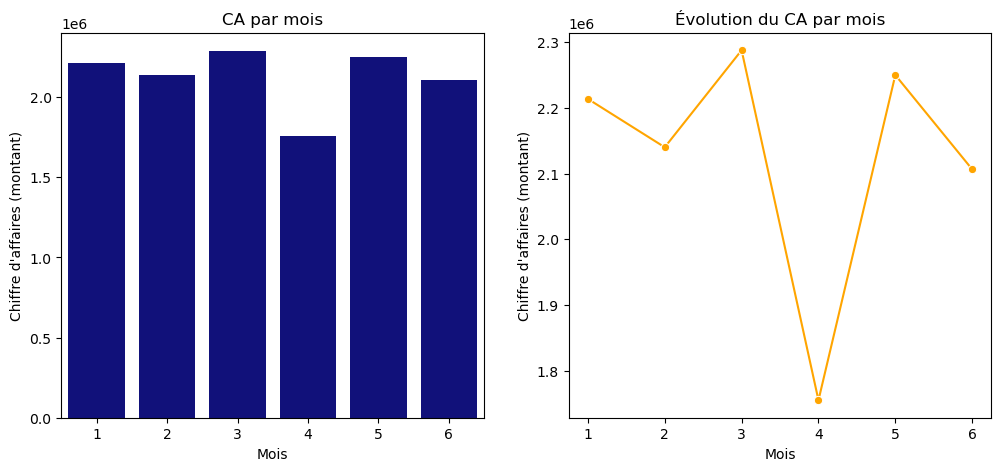

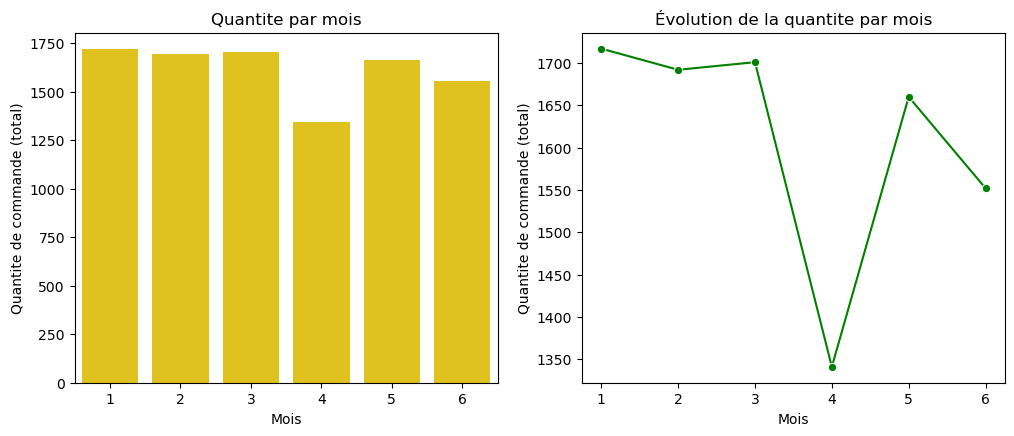

In [8]:
# CA par mois
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

sns.barplot(x=info_mois.index, y=info_mois['montant'], color='darkblue')
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (montant)")
plt.title("CA par mois")

plt.subplot(1,2,2)

sns.lineplot(x=info_mois.index, y=info_mois['montant'], marker="o", color="orange")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (montant)")
plt.title("Évolution du CA par mois")


# Quantite par mois
plt.figure(figsize=(12,10))

plt.subplot(2,2,1)

sns.barplot(x=info_mois.index, y=info_mois['quantite'], color='gold')
plt.xlabel("Mois")
plt.ylabel("Quantite de commande (total)")
plt.title("Quantite par mois")

plt.subplot(2,2,2)

sns.lineplot(x=info_mois.index, y=info_mois['quantite'], marker="o", color="green")
plt.xlabel("Mois")
plt.ylabel("Quantite de commande (total)")
plt.title("Évolution de la quantite par mois")

plt.show()

### Analyse par boutique

In [9]:
# Sur la quantite

quant_boutique = df.pivot_table(index=df['mois'], values='quantite', columns='boutique', aggfunc='sum')
quant_boutique

boutique,Agoè,Bè,Kégué,Tokoin
mois,,,,
1,440.0,391.0,338.0,548.0
2,434.0,395.0,338.0,525.0
3,414.0,360.0,382.0,545.0
4,467.0,334.0,292.0,248.0
5,426.0,384.0,309.0,541.0
6,375.0,366.0,324.0,487.0


In [10]:
# Sur le montant

ca_boutique = df.pivot_table(index=df['mois'], values='montant', columns='boutique', aggfunc='sum')
ca_boutique

boutique,Agoè,Bè,Kégué,Tokoin
mois,,,,
1,591700,429600,497150,695300
2,551600,530550,438450,619550
3,529450,509800,544400,704250
4,587850,400250,412400,354400
5,526050,571150,436350,716550
6,479850,507600,462450,656600


**Lecture rapide** :
 - La baisse de quantité en Avril provient principalement de la `boutique de Tokoin` passant ~520 en moyenne à 248 soit une **`baisse de ~50%`**
 - La boutique de Tokoin est suivi par celle de `Kégué` passant de ~330 en moyenne à 292
 - A remarquer les quantités vendues par la boutique de `Agoe` à quant elle augmenter

### Pourquoi le mois d'Avril particullierement ?

 - Ma premiere pensée va vers le nombre de jour d'ouverture de chacune des boutiques et le nombre de quantite quotidienne (à vérifier)
 - Une autre cause pourrait etre le stock (indisponible dans ces données)

In [11]:
df.groupby(['boutique', 'mois'])['jour'].nunique()

boutique  mois
Agoè      1       31
          2       28
          3       31
          4       30
          5       31
          6       30
Bè        1       31
          2       28
          3       31
          4       30
          5       31
          6       30
Kégué     1       31
          2       28
          3       31
          4       29
          5       31
          6       30
Tokoin    1       31
          2       28
          3       31
          4       23
          5       31
          6       30
Name: jour, dtype: int64

**Lecture rapide** :
 - Avec les chiffres ci-dessus, on a enfin une premiere idée de l'explication de la chose : **`La boutique de Tokoin était ouvert en Avril 23jours / 30(fermée 23,33% du temps)`** : ce qui ne traduit pas encore ~350.000Fcfa / 533.000 de perte

In [12]:
avril = df.loc[(df['mois'] == 4)]

avril_quant = avril.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
pd.set_option('display.max_columns', None)

#Remplis les jours sans quantite de 0
avril_quant = avril_quant.fillna(0)
avril_quant

jour,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
boutique,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Agoè,15.0,23.0,8.0,19.0,7.0,20.0,7.0,9.0,10.0,17.0,21.0,10.0,26.0,16.0,17.0,15.0,22.0,23.0,10.0,8.0,8.0,19.0,18.0,18.0,18.0,17.0,17.0,17.0,16.0,16.0
Bè,11.0,16.0,9.0,10.0,12.0,11.0,15.0,16.0,16.0,20.0,6.0,5.0,10.0,4.0,4.0,17.0,16.0,13.0,1.0,8.0,7.0,8.0,13.0,8.0,24.0,5.0,9.0,18.0,16.0,6.0
Kégué,11.0,16.0,10.0,6.0,4.0,6.0,8.0,16.0,21.0,5.0,23.0,0.0,12.0,18.0,9.0,5.0,9.0,14.0,4.0,15.0,6.0,8.0,10.0,9.0,11.0,7.0,4.0,9.0,8.0,8.0
Tokoin,6.0,12.0,4.0,26.0,8.0,14.0,7.0,28.0,9.0,13.0,30.0,21.0,24.0,17.0,3.0,0.0,0.0,4.0,1.0,0.0,0.0,2.0,0.0,5.0,5.0,0.0,4.0,1.0,0.0,4.0


In [13]:
moy_1 = avril_quant.iloc[3, :16].mean()
moy_2 = avril_quant.iloc[3, 16:31].mean()
print(f"Moyenne de quantite 2 premieres semaines : {moy_1}")
print(f"Moyenne de quantite 2 dernieres semaines : {moy_2}")

Moyenne de quantite 2 premieres semaines : 13.875
Moyenne de quantite 2 dernieres semaines : 1.8571428571428572


**Lecture rapide** :
 - Au dela de ces 7 jours d'inactivité à partir du `14 Avril` la boutique de Tokoin a connu une **`chute de commande passant de 13.8 à ~1.8 en moyenne jusqu'à début Mai`**

In [14]:
# Quantite durant le mois de Mai

mai = df.loc[(df['mois'] == 5)]
mai_quant = mai.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
mai_quant = mai_quant.fillna(0)

moy_mai = mai_quant.iloc[3, :8].mean()
print(f"Moyenne de quantite  premiere semaine (Mai) : {moy_mai}")

Moyenne de quantite  premiere semaine (Mai) : 16.75


**Lecture rapide** :
 - La premiere semaine du mois de `Mai` a repris avec une quantite de `~16.7`

### Comparaison des quantites de Tokoin entre Janvier et Juin

In [15]:
janvier = df.loc[(df['mois'] == 1)]
janvier_quant = janvier.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
janvier_quant = janvier_quant.fillna(0)


fevrier = df.loc[(df['mois'] == 2)]
fevrier_quant = fevrier.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
fevrier_quant = fevrier_quant.fillna(0)


mars = df.loc[(df['mois'] == 3)]
mars_quant = mars.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
mars_quant = mars_quant.fillna(0)


juin = df.loc[(df['mois'] == 6)]
juin_quant = juin.pivot_table(index='boutique', values='quantite', columns='jour', aggfunc='sum')
juin_quant = juin_quant.fillna(0)

##### Représentation

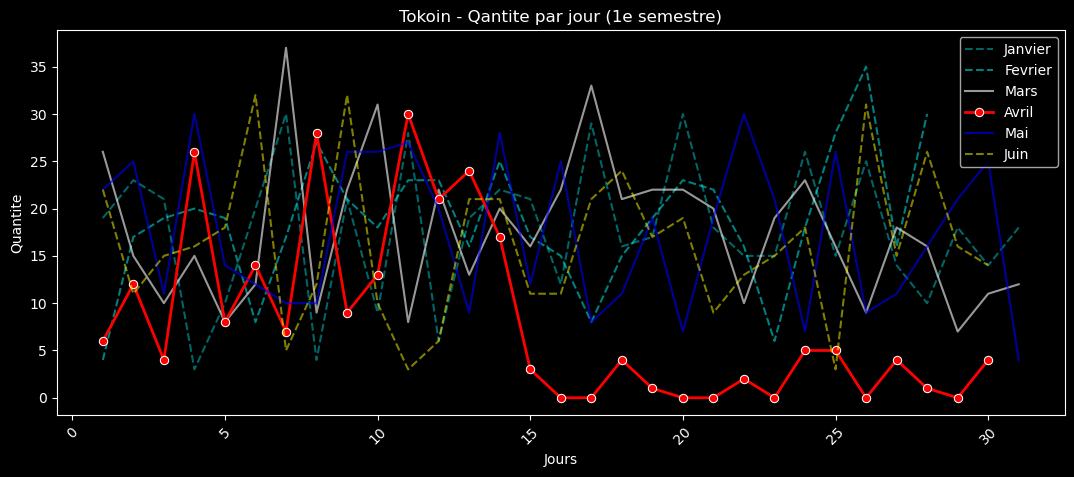

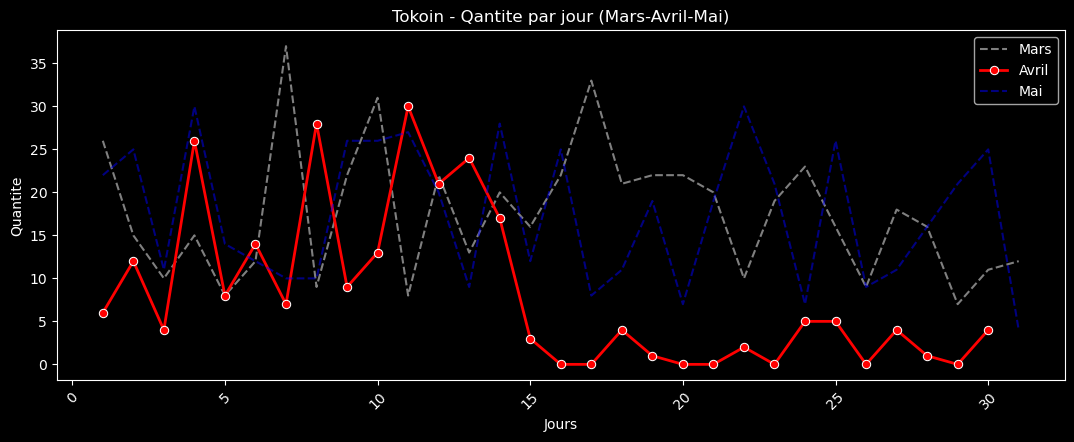

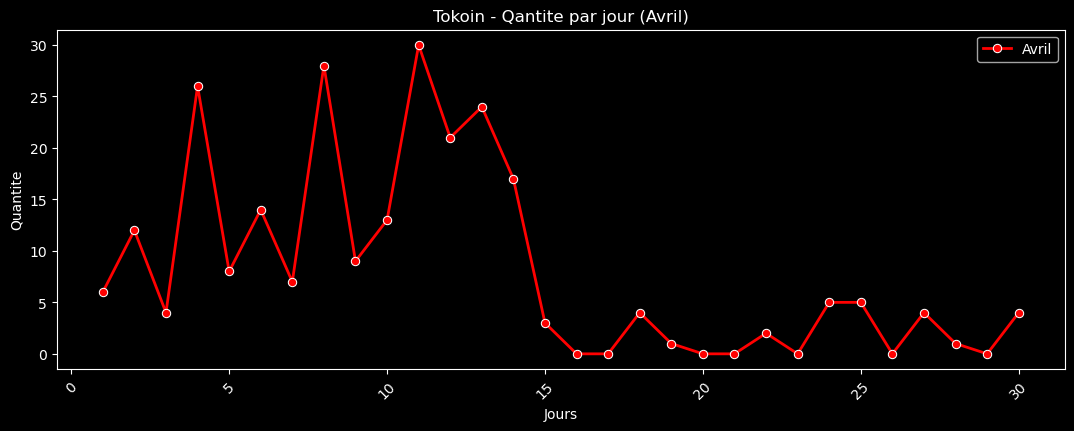

In [16]:
plt.style.use('dark_background') # Coulur background


# Premier Semestre
plt.figure(figsize=(13,5))
plt.subplot(1,1,1)

sns.lineplot(janvier_quant.iloc[3, :], color='cyan', alpha=0.4, label='Janvier', ls='--')
sns.lineplot(fevrier_quant.iloc[3, :], color='cyan', alpha=0.5, label='Fevrier',ls='--')
sns.lineplot(mars_quant.iloc[3, :], color='white', alpha=0.6, label='Mars')
sns.lineplot(avril_quant.iloc[3, :], marker='o', color='red', label='Avril', lw=2)
sns.lineplot(mai_quant.iloc[3, :], color='blue', alpha=0.6, label='Mai')
sns.lineplot(juin_quant.iloc[3, :], color='yellow', alpha=0.5, label='Juin', ls='--')

plt.title("Tokoin - Qantite par jour (1e semestre)")
plt.xlabel("Jours")
plt.ylabel("Quantite")
plt.xticks(rotation=45)



# Mars - Avril - Mai
plt.figure(figsize=(13,10))
plt.subplot(2,1,1)

sns.lineplot(mars_quant.iloc[3, :], color='white', alpha=0.5, label='Mars', ls='--')
sns.lineplot(avril_quant.iloc[3, :], marker='o', color='red', label='Avril', lw=2)
sns.lineplot(mai_quant.iloc[3, :], color='blue', alpha=0.5, label='Mai', ls='--')

plt.title("Tokoin - Qantite par jour (Mars-Avril-Mai)")
plt.xlabel("Jours")
plt.ylabel("Quantite")
plt.xticks(rotation=45)



# Uniquement Avril
plt.figure(figsize=(13,15))
plt.subplot(3,1,1)

sns.lineplot(avril_quant.iloc[3, :], marker='o', color='red', label='Avril', lw=2)

plt.title("Tokoin - Qantite par jour (Avril)")
plt.xlabel("Jours")
plt.ylabel("Quantite")
plt.xticks(rotation=45)


plt.show()

# CONCLUSION

 - **`Le CA d’avril (1,75 M FCFA) est inférieur de ~24% à celui de mars (2,29 M)`**
 - **`Cette baisse vient surtout de la boutique de Tokoin (environ -350 000 FCFA sur -533 000, soit les deux tiers)`**
 - **`Cette boutique a vendu environ 7 fois moins à partir du 15 avril (1.8 vente par jour contre 13.8 avant), puis est revenue à la normale en mai`**
 - **`La quantite moyenne est stable les deux premieres semaines, donc le problème est un manque de ventes, pas de prix`**
 - **`Les variations de Kégué et Bè restent dans la fluctuation normale`**
 - **`Cause probable à confirmer avec le gérant de Tokoin : travaux, fermeture partielle ou rupture de stock du 15 au 30 avril.`**